# Normalization, Dependency Handling and Data Preparation

This notebook prepares the features for modelling and defines how **vehicle-driver dependency** is reduced and evaluated.

## Leakage-free design
Every step that learns from data is fitted **inside each validation fold using training data only**. Steps that use no labels are applied per trip.

| Step | Uses labels? | Fitted on | Where |
|---|---|---|---|
| Exclusion of slow, mixed-label, speed-bump windows | no | – (fixed rules) | this notebook |
| Manoeuvre filtering | no | – (fixed thresholds), applied to training windows only | fold |
| Speed normalisation (log-log slope, within class) | yes | training windows of the fold | fold |
| Per-trip normalisation (robust median / IQR) | no | all moving windows of each trip | per trip |
| Cross-vehicle stable feature selection | yes | training vehicles of the fold | fold |
| Z-score scaling (`StandardScaler`) | no | training windows of the fold (inside the model pipeline) | fold |

The earlier Notebook 04 correctly fitted the scaler on the training data only. This design keeps that principle and extends it to all data-dependent steps and to all validation folds.

## Vehicle-driver dependency handling
| Source of dependency | Effect | Handling |
|---|---|---|
| Sensor orientation | vibration split differently over x, y, z | orientation-invariant channels (Notebook 03) |
| Suspension, mass, tyres | vibration **amplitude** scaled per vehicle | relative band powers; per-trip normalisation |
| Driver speed choice | amplitude grows with speed; drivers slow down on bad roads differently | speed normalisation; raw speed removed as a feature |
| Driver manoeuvres | turning/braking create non-road signals | manoeuvre filtering of training windows |
| Vehicle-specific feature behaviour | some features separate classes for one vehicle only | cross-vehicle stable feature selection |

**Confound:** in PVS each vehicle has exactly one driver, so vehicle and driver effects cannot be separated. All results refer to the combined vehicle-driver context.

In [1]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [3]:
data = c4.load_data()
print('Thresholds:', data.th)
display(data.summary())

Thresholds: {'min_purity': 0.8, 'min_speed': 1.0, 'lat_acc_max': 1.5, 'long_acc_max': 1.0}


,all windows,moving,labelled usable (L),evaluation set (E),bump windows,manoeuvre %
Fiat Bravo,3621,3449,3170,2784,95,12.2
Fiat Palio,3433,3251,2980,2644,93,11.3
VW Saveiro,3741,3456,3118,2851,101,8.6


## 1. Validation strategies
| Strategy | Train | Test | Purpose |
|---|---|---|---|
| Random 80/20 | 80 % of windows | 20 % of windows | optimistic reference (overlapping windows and identical roads in train and test) |
| LOVO – leave-one-vehicle-out | two vehicle-drivers | third vehicle-driver | **main test of cross-vehicle-driver generalisation** (3 folds) |
| LORO – leave-one-route-out | two scenarios | third scenario | generalisation to unseen roads |
| LOVO+LORO | other vehicles on other routes | one vehicle on one route | strictest test (9 folds) |

The earlier experiment (train PVS1–6, test PVS7–9) is the LOVO fold *test = Fiat Palio*. **Performance degradation** = Random macro-F1 − LOVO macro-F1.

In [4]:
rows = []
for sname, folds in data.splits().items():
    for fname, trm, tem in folds:
        rows.append({'strategy': sname, 'fold': fname, 'train windows': int((trm & data.L).sum()),
                     'test windows (E)': int((tem & data.E).sum())})
display(pd.DataFrame(rows))

dist = pd.crosstab(data.A.vehicle[data.E], pd.Series(data.y[data.E], index=data.A.index[data.E]).map(dict(enumerate(CL))),
                   normalize='index').mul(100).round(1)[CL]
print('Class distribution of the evaluation windows (%):')
display(dist)

,strategy,fold,train windows,test windows (E)
0,Random,random 80/20,7414,1670
1,LOVO,test=Fiat Bravo,6098,2784
2,LOVO,test=Fiat Palio,6288,2644
3,LOVO,test=VW Saveiro,6150,2851
4,LORO,test=route1,5929,2869
5,LORO,test=route2,5918,3059
6,LORO,test=route3,6689,2351
7,LOVO+LORO,test=Fiat Bravo/route1,3874,951
8,LOVO+LORO,test=Fiat Bravo/route2,3933,1062
9,LOVO+LORO,test=Fiat Bravo/route3,4389,771


Class distribution of the evaluation windows (%):


col_0,good,regular,bad
vehicle,,,
Fiat Bravo,33.8,44.0,22.2
Fiat Palio,39.0,41.9,19.1
VW Saveiro,39.2,43.6,17.2


## 2. Evidence: vehicle dependency of a feature before and after handling
Vertical RMS acceleration of the left dashboard sensor, per class and vehicle. Before handling, the same road class produces different levels in different vehicles; after speed and per-trip normalisation, the vehicles should overlap more while the classes stay separated.

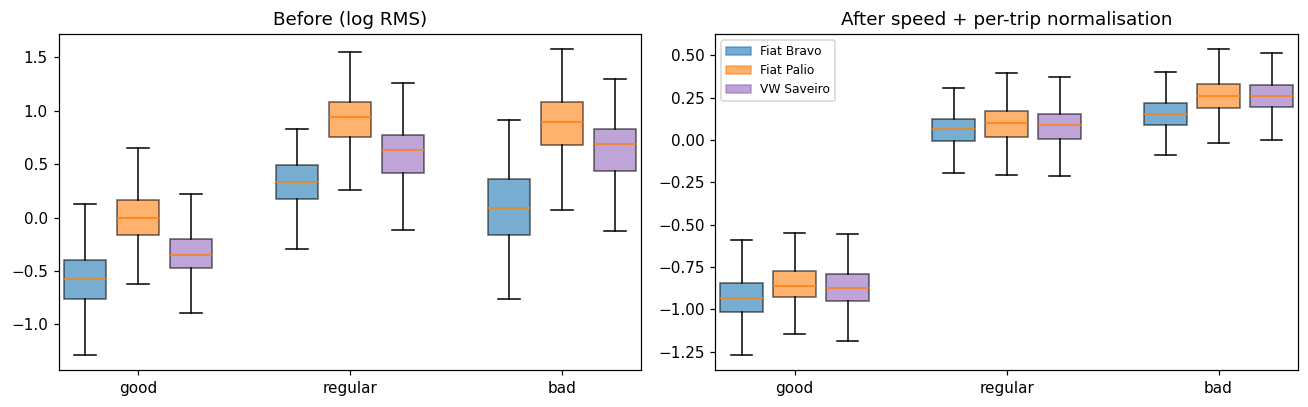

In [5]:
cfgs = c4.ablation_configs()
feat = 't__left_dashboard__acc_vert__rms'
Lidx = np.where(data.L)[0]
X_before = c4.config_columns(data, cfgs['C2 + Invariant repr.'])
X_after, _ = c4.prepare(data, cfgs['C5 + Per-trip normalisation'], Lidx)
vehicles = sorted(data.A.vehicle.unique())
vcol = dict(zip(vehicles, ['tab:blue', 'tab:orange', 'tab:purple']))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, vals, title in [(ax[0], np.log(X_before[feat].values + 1e-9), 'Before (log RMS)'),
                       (ax[1], X_after[feat].values, 'After speed + per-trip normalisation')]:
    pos, box, col = [], [], []
    for j in range(3):
        for i, v in enumerate(vehicles):
            m = data.E & (data.y == j) & (data.A.vehicle.values == v)
            if m.sum():
                box.append(vals[m]); pos.append(j * 4 + i); col.append(vcol[v])
    bp = a.boxplot(box, positions=pos, widths=.8, patch_artist=True, showfliers=False)
    for patch, c in zip(bp['boxes'], col): patch.set_facecolor(c); patch.set_alpha(.6)
    a.set_xticks([1, 5, 9], CL); a.set_title(title)
ax[1].legend([plt.Rectangle((0, 0), 1, 1, color=vcol[v], alpha=.6) for v in vehicles], vehicles, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'dependency_feature_before_after.png'), dpi=150); plt.show()

## 3. Evidence: vehicle identifiability
A Random Forest is trained to predict **which vehicle-driver** produced each window, using cross-validation over whole trips. If dependency handling works, the features carry less vehicle information and this accuracy drops towards chance level (0.33).

In [6]:
vid = pd.Series({name: c4.vehicle_identifiability(data, cfgs[name]) for name in
                 ['C0 Baseline (raw)', 'C1 + Noise handling', 'C2 + Invariant repr.',
                  'C4 + Speed normalisation', 'C5 + Per-trip normalisation']},
                name='vehicle balanced accuracy').round(3)
display(vid.to_frame())
vid.to_csv(os.path.join(c4.RESULTS_DIR, 'vehicle_identifiability.csv'))

,vehicle balanced accuracy
C0 Baseline (raw),0.976
C1 + Noise handling,0.974
C2 + Invariant repr.,0.964
C4 + Speed normalisation,0.967
C5 + Per-trip normalisation,0.706


## 4. Speed normalisation slopes
The fitted exponents *b* in feature ∝ speed^b show how strongly each amplitude feature grows with speed (fitted within class, on all labelled windows here for illustration; inside the experiments they are fitted on training folds only).

In [7]:
slopes, _ = c4.fit_speed_slopes(data, c4.config_columns(data, cfgs['C4 + Speed normalisation']), Lidx)
sl = pd.Series(slopes).sort_values()
display(pd.concat([sl.head(5), sl.tail(10)]).round(3).to_frame('exponent b'))

,exponent b
t__left_dashboard__gyro_fz__iqr,-0.206
t__left_dashboard__gyro_fz__rms,-0.202
t__left_dashboard__gyro_fz__std,-0.187
t__right_dashboard__gyro_fz__rms,-0.169
t__right_dashboard__gyro_fz__iqr,-0.162
t__right_dashboard__acc_vert__rms,0.635
t__right_dashboard__acc_vert__std,0.635
t__left_dashboard__acc_dz__rms,0.644
t__left_dashboard__acc_dz__std,0.644
t__left_dashboard__acc_vert__rms,0.645


## 5. Summary
* Data preparation is leakage-free: every data-dependent step is fitted within each fold on training data only.
* Four validation strategies are defined; LOVO is the main generalisation test and includes the earlier PVS1–6 → PVS7–9 experiment as one of its folds.
* The dependency-handling steps are implemented and their effect on feature distributions and vehicle identifiability is shown above. Their effect on classification is measured in Notebook 06.